# 05 · Transaction costs

Notebooks 02 and 03 score every model on a one-day hedging error with no trading in it. A hedge ratio that changes more from day to day costs more to maintain, so a model could win on error and lose it back in costs. This notebook follows each option over a multi-day **hedging episode** and charges for every trade in the index.

For a short option hedged with $\delta_t$ units of the index, the profit and loss on day $t$ is

$$
\text{P\&L}_t = -(V_{t+1}-V_t) + \delta_t\,(S_{t+1}-S_t) - c\,|\delta_t-\delta_{t-1}|\,S_t ,
$$

with $c$ the proportional cost per unit of index notional traded (1 bp $=10^{-4}$). An episode is a run of consecutive trading days on which the contract is in the sample; the hedge is set up from zero on the first day and taken off after the last, and both trades are charged. See `src/costs.py`.

Models are the ones fitted in notebooks 02 and 03 (2016–18), read from their saved predictions. Nothing is fitted here. 2020 is the test year; 2019 is shown next to it as the calm-year contrast.

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from config import *
from src import costs, evaluate, store

SAMPLE = os.environ.get("MF703_SAMPLE", "main")   # "main" = all quoted options, "traded_only" = volume > 0
P = sample_paths(SAMPLE)
TAB = P["tables"] / "costs"; TAB.mkdir(parents=True, exist_ok=True); P["figures"].mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:.3f}".format); pd.set_option("display.width", 200)

CANDIDATES = ["hw", "gbm", "nn_direct", "nn_resid", "nn_resid_hw"]
MODELS = [m for m in CANDIDATES if (P["predictions"] / f"{m}.parquet").exists()]   # whatever notebooks 02-03 saved
DELTAS = ["delta"] + [f"delta_{m}" for m in MODELS]
LABEL = {"delta": "bs", **{f"delta_{m}": m for m in MODELS}}
COLOR = {m: f"C{i}" for i, m in enumerate(["bs"] + CANDIDATES)}   # one colour per model in every figure
YEARS = [2019, 2020]
BPS = (0, 0.5, 1, 2, 5, 10)                     # index futures cost well under 1 bp; 5-10 bp is a stress level
print(SAMPLE, "| models:", MODELS)

main | models: ['hw', 'gbm', 'nn_direct', 'nn_resid', 'nn_resid_hw']


In [2]:
data = {}
for yr in YEARS:
    p = store.load_pairs(P["pairs"], columns=store.MODEL_COLUMNS + ["date_next"], years=[yr])
    p = store.load_predictions(p, MODELS, P["predictions"])
    data[yr] = costs.sort_for_episodes(p)

rows = []
for yr, p in data.items():
    n = p.groupby("episode").size()
    rows.append({"year": yr, "pairs": len(p), "contracts": p.groupby(costs.KEY, observed=True).ngroups, "episodes": len(n),
                 "median days": n.median(), "90th pct days": n.quantile(0.9),
                 "episodes of 5+ days": int((n >= 5).sum()), "share of pairs in them": n[n >= 5].sum() / len(p)})
episodes = pd.DataFrame(rows).set_index("year"); episodes.to_csv(TAB / "episodes.csv"); episodes

,pairs,contracts,episodes,median days,90th pct days,episodes of 5+ days,share of pairs in them
year,,,,,,,
2019,1197815,51114,101239,7.000,31.000,63026,0.933
2020,1678281,62888,112852,7.000,42.000,65429,0.939


A contract usually gives more than one episode: it drops out when its delta leaves the 0.05–0.95 band or the vendor has no file for a day, and starts again when it returns. Episodes shorter than five days are left out of the episode-level tables below (they are almost all set-up and unwind); the day-level gain ratios use every pair.

## Check: at zero cost the simulation reproduces notebooks 02 and 03

In [3]:
for yr, p in data.items():
    a = costs.net_gain(p, MODELS, bps=(0,), by=["type"]).droplevel(0)
    b = evaluate.gain_table(p, MODELS, ["type"])[MODELS]
    assert np.allclose(a.to_numpy(), b.to_numpy(), atol=1e-9), yr
    print(yr); print(b.to_string())

2019
        hw   gbm  nn_direct  nn_resid  nn_resid_hw
type                                              
C    0.042 0.076      0.093     0.101        0.072
P    0.101 0.122      0.158     0.144        0.147


2020
        hw   gbm  nn_direct  nn_resid  nn_resid_hw
type                                              
C    0.191 0.156     -0.053    -0.079        0.168
P    0.161 0.067     -0.798    -0.116        0.135


## How much does each model trade?

Day-to-day rebalancing, $|\delta_t-\delta_{t-1}|$ averaged over all days inside episodes, in delta units per option per day. The second table is the same number relative to Black-Scholes.

In [4]:
rows = []
for yr, p in data.items():
    for typ, g in p.groupby("type", observed=True):
        s = costs.summarise(costs.hedge_pnl(g, DELTAS, cost_bp=0), DELTAS)
        rows.append(s["rebal_per_day"].rename(LABEL).rename((yr, typ)))
turnover = pd.DataFrame(rows); turnover.index = pd.MultiIndex.from_tuples(turnover.index, names=["year", "type"])
turnover.to_csv(TAB / "rebalancing_per_day.csv")
display(turnover.style.format("{:.4f}"))
(turnover.div(turnover["bs"], axis=0)).style.format("{:.2f}")

## Cost sweep, episode level

For each cost level: the mean and spread of an episode's total P&L (index points per option), the 5% worst episode, and the mean cost paid.

In [5]:
sweeps = {}
for yr, p in data.items():
    s = costs.cost_sweep(p, DELTAS, bps=BPS).rename(index=LABEL, level="model")
    s.to_csv(TAB / f"cost_sweep_{yr}.csv"); sweeps[yr] = s
show = ["mean_pnl", "std_pnl", "p05_pnl", "mean_cost"]
for yr in YEARS:
    print(yr, "| episodes:", int(sweeps[yr]["n_episodes"].iloc[0]))
    display(sweeps[yr].loc[[0, 1, 5], show])

2019 | episodes: 63026


mean_pnl  std_pnl  p05_pnl  mean_cost
cost_bp model                                             
0.000   bs              0.874    7.383  -11.361      0.000
        hw             -0.934    6.884  -13.039      0.000
        gbm            -0.984    6.277  -11.920      0.000
        nn_direct      -0.246    6.120  -10.557      0.000
        nn_resid       -0.407    6.225  -10.720      0.000
        nn_resid_hw    -0.564    6.491  -11.959      0.000
1.000   bs              0.448    7.418  -11.941      0.427
        hw             -1.359    6.911  -13.593      0.425
        gbm            -1.408    6.303  -12.452      0.424
        nn_direct      -0.663    6.146  -11.075      0.417
        nn_resid       -0.828    6.257  -11.264      0.421
        nn_resid_hw    -0.988    6.523  -12.561      0.424
5.000   bs             -1.260    7.618  -14.259      2.134
        hw             -3.057    7.080  -15.881      2.123
        gbm            -3.104    6.472  -14.623      2.120
        nn_direct      -2.332    6.310  -13.253      2.086
        nn_resid       -2.513    6.447  -13.478      2.106
        nn_resid_hw    -2.686    6.713  -14.880      2.122

2020 | episodes: 65429


mean_pnl  std_pnl  p05_pnl  mean_cost
cost_bp model                                             
0.000   bs            -14.475   54.285 -149.588      0.000
        hw            -14.536   46.990 -129.871      0.000
        gbm           -11.136   44.880 -114.061      0.000
        nn_direct     -11.389   50.881 -135.203      0.000
        nn_resid      -12.513   51.061 -140.274      0.000
        nn_resid_hw   -14.358   48.310 -133.303      0.000
1.000   bs            -15.037   54.382 -150.490      0.562
        hw            -15.092   47.088 -130.712      0.557
        gbm           -11.706   44.957 -114.918      0.571
        nn_direct     -11.920   50.957 -135.830      0.531
        nn_resid      -13.055   51.143 -141.128      0.543
        nn_resid_hw   -14.916   48.409 -134.145      0.558
5.000   bs            -17.285   54.782 -153.831      2.810
        hw            -17.319   47.495 -134.014      2.783
        gbm           -13.989   45.279 -118.222      2.853
        nn_direct     -14.046   51.276 -138.875      2.657
        nn_resid      -15.226   51.483 -143.976      2.713
        nn_resid_hw   -17.146   48.823 -137.436      2.788

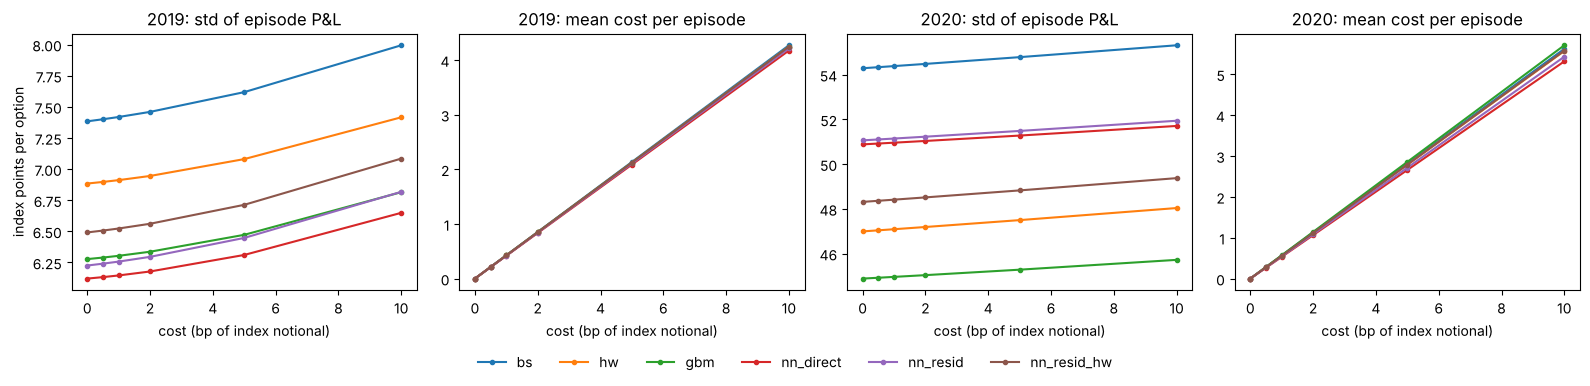

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for j, yr in enumerate(YEARS):
    sd = sweeps[yr]["std_pnl"].unstack("model")[list(LABEL.values())]
    co = sweeps[yr]["mean_cost"].unstack("model")[list(LABEL.values())]
    sd.plot(ax=axes[2 * j], marker="o", ms=3, legend=False, color=[COLOR[m] for m in sd.columns], title=f"{yr}: std of episode P&L")
    co.plot(ax=axes[2 * j + 1], marker="o", ms=3, legend=False, color=[COLOR[m] for m in co.columns], title=f"{yr}: mean cost per episode")
    for ax in axes[2 * j: 2 * j + 2]:
        ax.set_xlabel("cost (bp of index notional)")
axes[0].set_ylabel("index points per option")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=len(LABEL), frameon=False, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.savefig(P["figures"] / "costs_sweep.png", dpi=150, bbox_inches="tight")

## What the extra hedging accuracy costs

At 1 bp: how much each model lowers the spread of episode P&L relative to Black-Scholes, and how much more (or less) it pays in costs. Both in index points per option per episode.

In [7]:
rows = []
for yr in YEARS:
    s = sweeps[yr].loc[1]
    for m in MODELS:
        rows.append({"year": yr, "model": m, "std P&L, BS": s.loc["bs", "std_pnl"], "std P&L, model": s.loc[m, "std_pnl"],
                     "risk reduction": s.loc["bs", "std_pnl"] - s.loc[m, "std_pnl"],
                     "extra cost at 1 bp": s.loc[m, "mean_cost"] - s.loc["bs", "mean_cost"],
                     "cost, BS": s.loc["bs", "mean_cost"]})
tradeoff = pd.DataFrame(rows).set_index(["year", "model"]); tradeoff.to_csv(TAB / "risk_vs_cost_1bp.csv"); tradeoff

std P&L, BS  std P&L, model  risk reduction  extra cost at 1 bp  cost, BS
year model                                                                                 
2019 hw                 7.418           6.911           0.507              -0.002     0.427
     gbm                7.418           6.303           1.115              -0.003     0.427
     nn_direct          7.418           6.146           1.272              -0.010     0.427
     nn_resid           7.418           6.257           1.161              -0.006     0.427
     nn_resid_hw        7.418           6.523           0.896              -0.003     0.427
2020 hw                54.382          47.088           7.294              -0.005     0.562
     gbm               54.382          44.957           9.425               0.009     0.562
     nn_direct         54.382          50.957           3.425              -0.031     0.562
     nn_resid          54.382          51.143           3.239              -0.019     0.562
     nn_resid_hw       54.382          48.409           5.973              -0.004     0.562

## Gain ratio net of costs

The gain ratio of notebooks 02 and 03, recomputed on net-of-cost daily P&L, with the model and Black-Scholes charged the same cost:

$$
G(c) = 1 - \frac{\sum_t \text{P\&L}^{\text{model}}_t(c)^2}{\sum_t \text{P\&L}^{\text{BS}}_t(c)^2}.
$$

The grid runs to 100 bp, far beyond any realistic cost for the index, to see where the ranking would change.

type             C                                          P                                     
                hw   gbm nn_direct nn_resid nn_resid_hw    hw   gbm nn_direct nn_resid nn_resid_hw
year cost_bp                                                                                      
2019 0.000   0.042 0.076     0.093    0.101       0.072 0.101 0.122     0.158    0.144       0.147
     1.000   0.041 0.075     0.093    0.100       0.071 0.101 0.122     0.160    0.145       0.148
     5.000   0.038 0.069     0.086    0.093       0.067 0.101 0.122     0.166    0.145       0.148
     20.000  0.034 0.041     0.045    0.043       0.048 0.077 0.091     0.159    0.116       0.118
2020 0.000   0.191 0.156    -0.053   -0.079       0.168 0.161 0.067    -0.798   -0.116       0.135
     1.000   0.191 0.156    -0.053   -0.079       0.168 0.161 0.067    -0.797   -0.116       0.135
     5.000   0.190 0.155    -0.053   -0.079       0.167 0.161 0.068    -0.795   -0.115       0.135
     20.000  0.183 0.149    -0.051   -0.076       0.160 0.157 0.068    -0.764   -0.108       0.132

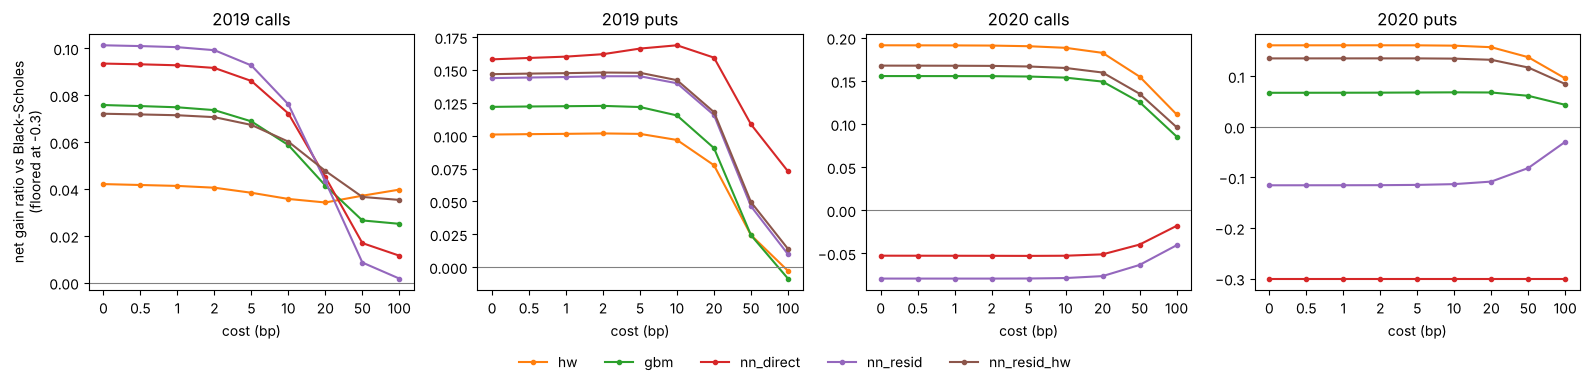

In [8]:
GRID = (0, 0.5, 1, 2, 5, 10, 20, 50, 100)
net = pd.concat({yr: costs.net_gain(p, MODELS, bps=GRID, by=["type"]) for yr, p in data.items()}, names=["year"])
net.to_csv(TAB / "net_gain_by_cost.csv")
display(net.loc[pd.IndexSlice[:, [0, 1, 5, 20], :], :].unstack("type").swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (yr, typ) in zip(axes, [(y, t) for y in YEARS for t in ("C", "P")]):
    t = net.loc[yr].xs(typ, level="type")
    for m in MODELS:
        ax.plot(range(len(t)), t[m].clip(lower=-0.3), marker="o", ms=3, label=m, color=COLOR[m])
    ax.axhline(0, color="grey", lw=0.8); ax.set_xticks(range(len(t))); ax.set_xticklabels([f"{b:g}" for b in t.index])
    ax.set_title(f"{yr} {'calls' if typ == 'C' else 'puts'}"); ax.set_xlabel("cost (bp)")
axes[0].set_ylabel("net gain ratio vs Black-Scholes\n(floored at -0.3)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=len(MODELS), frameon=False, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.savefig(P["figures"] / "costs_net_gain.png", dpi=150, bbox_inches="tight")

## One day against the whole episode

Notebooks 02 and 03 rank models by the sum of squared **one-day** errors. A desk carries the hedge for the whole episode, so the spread of the episode's **total** P&L is the risk it ends up with. The table puts the two next to each other at 1 bp: the day-level gain ratio, and the same ratio computed on episode totals, $1 - \sum_e \text{P\&L}_e^2 \big/ \sum_e \text{P\&L}_{e,\text{BS}}^2$ (episodes of five days or more).

In [9]:
rows = []
for yr, p in data.items():
    ep = costs.hedge_pnl(p, DELTAS, cost_bp=1)
    day = costs.net_gain(p, MODELS, bps=(1,), by=["type"]).droplevel(0)
    for typ, g in ep.groupby("type", observed=True):
        bs2 = (g["pnl_delta"] ** 2).sum()
        for m in MODELS:
            rows.append({"year": yr, "type": typ, "model": m, "one-day gain": day.loc[typ, m],
                         "episode gain": 1 - (g[f"pnl_delta_{m}"] ** 2).sum() / bs2})
horizon = pd.DataFrame(rows).set_index(["year", "type", "model"]).unstack("model")
horizon.to_csv(TAB / "gain_day_vs_episode_1bp.csv"); horizon

one-day gain                                      episode gain                                     
model              gbm    hw nn_direct nn_resid nn_resid_hw          gbm    hw nn_direct nn_resid nn_resid_hw
year type                                                                                                    
2019 C           0.075 0.041     0.093    0.100       0.071        0.216 0.045     0.263    0.297       0.130
     P           0.122 0.101     0.160    0.145       0.148        0.269 0.149     0.345    0.264       0.280
2020 C           0.156 0.191    -0.053   -0.079       0.168        0.320 0.188     0.194    0.113       0.150
     P           0.067 0.161    -0.797   -0.116       0.135        0.324 0.277     0.085    0.137       0.239

## Distribution of episode P&L in 2020 at 1 bp

,1%,5%,median,95%
bs,-208.484,-150.490,1.731,36.001
hw,-188.551,-130.712,-0.429,28.678
gbm,-190.871,-114.918,0.156,32.870
nn_direct,-197.788,-135.830,1.099,39.850
nn_resid,-197.092,-141.128,1.394,36.874
nn_resid_hw,-193.153,-134.145,-0.029,30.101


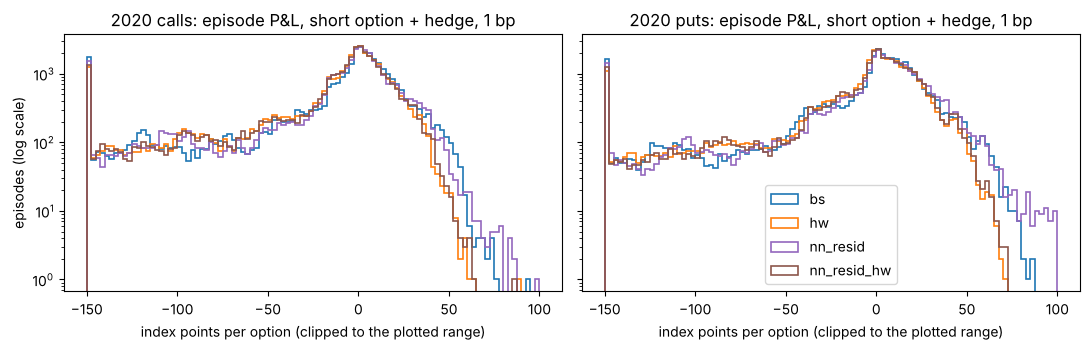

In [10]:
pnl = costs.hedge_pnl(data[2020], DELTAS, cost_bp=1)
pick = [c for c in ["delta", "delta_hw", "delta_nn_resid", "delta_nn_resid_hw"] if c in DELTAS]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
bins = np.linspace(-150, 100, 101)
for ax, typ in zip(axes, ("C", "P")):
    g = pnl[pnl["type"] == typ]
    for c in pick:
        ax.hist(g[f"pnl_{c}"].clip(bins[0], bins[-1]), bins=bins, histtype="step", lw=1.2, label=LABEL[c], color=COLOR[LABEL[c]])
    ax.set_yscale("log"); ax.set_title(f"2020 {'calls' if typ == 'C' else 'puts'}: episode P&L, short option + hedge, 1 bp")
    ax.set_xlabel("index points per option (clipped to the plotted range)")
axes[0].set_ylabel("episodes (log scale)"); axes[1].legend()
plt.tight_layout(); plt.savefig(P["figures"] / "costs_pnl_distribution_2020.png", dpi=150, bbox_inches="tight")
q = pd.DataFrame({LABEL[c]: pnl[f"pnl_{c}"].quantile([0.01, 0.05, 0.5, 0.95]) for c in DELTAS}).T
q.columns = ["1%", "5%", "median", "95%"]; q.to_csv(TAB / "pnl_quantiles_2020_1bp.csv"); q

## Findings

Main sample, models fitted on 2016–18, daily rebalancing, proportional cost on the index leg.

1. **The models do not trade more than Black-Scholes.** Day-to-day rebalancing is 0.022–0.035 delta units per option per day for every model, between 0.85 and 1.06 times the Black-Scholes figure depending on year and option type. The learned corrections shift the level of the hedge ratio; they do not make it jump around.

2. **So costs are almost the same for every model.** At 1 bp an episode costs about 0.43 index points per option in 2019 and 0.56 in 2020, most of it setting the hedge up and taking it off. The difference between any model and Black-Scholes is at most 0.03 points, against a reduction in the spread of episode P&L of 0.5–1.3 points in 2019 and 3.2–9.4 points in 2020 (`risk_vs_cost_1bp.csv`).

3. **Transaction costs do not change any conclusion of notebooks 02 and 03.** The net gain ratio is flat from 0 to 5 bp and the ranking of the models does not change over that range in either year. Index futures cost well under 1 bp to trade, so the realistic range is the flat part. Only at 20 bp and beyond do the networks' 2019 gains for calls shrink towards Hull-White's, and that is not a cost anyone hedging the S&P 500 pays.

4. **The ranking does depend on the horizon, and this was not expected.** Scored on the total P&L of an episode instead of one day at a time (`gain_day_vs_episode_1bp.csv`, calls / puts):

   | 2020 | one-day gain | episode gain |
   |---|---|---|
   | Hull-White | 0.191 / 0.161 | 0.188 / 0.277 |
   | LightGBM | 0.156 / 0.067 | 0.320 / 0.324 |
   | `nn_direct` | −0.053 / −0.797 | 0.194 / 0.085 |
   | `nn_resid` | −0.079 / −0.116 | 0.113 / 0.137 |
   | `nn_resid_hw` | 0.168 / 0.135 | 0.150 / 0.239 |

   Every model beats Black-Scholes over the episode, including the paper's networks, which lose to it day by day, and LightGBM moves ahead of Hull-White. In 2019 the networks' lead over Hull-White is larger at the episode level than at the one-day level (calls 0.26–0.30 against 0.04).

   A likely reason, **not tested here**: a hedge ratio that is off by a steady amount $b$ makes a daily error $b\,\Delta S_t$. Squared day by day, the large up and down days of March 2020 all count. Summed over an episode they largely cancel, leaving $b\,(S_{\text{end}}-S_{\text{start}})$. The one-day metric punishes a level error in the hedge ratio much harder than the episode metric does.

   **Read this with care.** Episodes overlap in time and all share the single path the index took in 2020, so the episode-level numbers rest on far fewer independent observations than the 250 trading days behind the one-day numbers. It is a reason to report both horizons, not evidence that the networks are safe in a crisis.

5. **Mean P&L differs between models for a reason that has nothing to do with costs.** At zero cost the short-option hedge earns +0.87 points per episode with the Black-Scholes delta in 2019 and −0.93 with Hull-White. Hull-White holds less of the index against a short call and is shorter against a short put, and the index rose 29% that year. A minimum-variance hedge lowers the variance of the P&L; it also changes the directional exposure that is left.

**What this simulation leaves out.** Only the index leg is charged; the option is sold once and held, at mid prices. Rebalancing is daily because the data are end-of-day. Financing and margin are ignored. The cost is proportional, with no market impact.

**Answer for the report.** The hedging gains from notebooks 02 and 03 survive realistic transaction costs untouched, because the better hedges need no more trading than the Black-Scholes hedge. Which model is best depends more on the horizon over which risk is measured than on costs.
